# Blok 1 · ROZWIĄZANIA zadania grupowego

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [ ]:
# wczytanie danych: lokalnie z repo (folder data/), w Colabie z GitHuba
URL = "https://raw.githubusercontent.com/ml-course-pg/ml-course-pg-2026/main/01-wprowadzenie/data/hotels.csv"
try:
    df = pd.read_csv("data/hotels.csv")
except FileNotFoundError:
    df = pd.read_csv(URL)

print("wymiary:", df.shape)
df.head()

wymiary: (10000, 28)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,City Hotel,1,38,2017,January,4,27,0,2,2,...,0,A,No Deposit,9.0,NaN,0,Transient,97.50,0,1
1,Resort Hotel,0,0,2016,February,7,8,1,5,2,...,0,A,No Deposit,241.0,NaN,0,Group,46.66,0,0
2,City Hotel,0,36,2016,December,53,28,0,4,2,...,0,A,No Deposit,9.0,NaN,0,Transient,168.73,0,0
3,Resort Hotel,0,17,2016,December,53,31,2,1,1,...,1,A,No Deposit,NaN,NaN,0,Transient,39.00,0,2
4,City Hotel,0,35,2016,February,7,12,0,2,2,...,0,A,No Deposit,9.0,NaN,0,Transient,80.30,0,1


## Krok 1: EDA — poznajcie swoje dane (~5 min)

Zanim cokolwiek zbudujecie, odpowiedzcie na trzy pytania:

a. **Które kolumny mają braki i ile procent?**

b. **Czy klasy targetu są zbalansowane?**

c. **Które cechy najmocniej wiążą się z anulowaniem?**

In [3]:
braki = df.isna().sum()
procent = (braki / len(df) * 100).round(1)
pd.DataFrame({"braki": braki, "%": procent})[braki > 0]

,braki,%
children,1,0.0
country,44,0.4
agent,1359,13.6
company,9430,94.3


In [4]:
print(f"anulowanych: {df['is_canceled'].mean():.1%}")
print()
print(df.groupby("deposit_type")["is_canceled"].mean().round(2))
print()
print(df.groupby("hotel")["is_canceled"].mean().round(2))
print()
print(df.groupby("is_canceled")[["lead_time", "previous_cancellations", "total_of_special_requests"]].mean().round(1))

anulowanych: 37.0%

deposit_type
No Deposit    0.28
Non Refund    1.00
Refundable    0.00
Name: is_canceled, dtype: float64

hotel
City Hotel      0.41
Resort Hotel    0.28
Name: is_canceled, dtype: float64

             lead_time  previous_cancellations  total_of_special_requests
is_canceled                                                              
0                 77.5                     0.0                        0.7
1                144.1                     0.2                        0.3


In [5]:
pd.set_option('display.max_columns', None)

df.describe(include="all")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
count,10000,10000.000000,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,9999.000000,10000.000000,10000,9956,10000,10000,10000.000000,10000.00000,10000.000000,10000,10000,8641.000000,570.000000,10000.000000,10000,10000.000000,10000.000000,10000.00000
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,98,7,5,NaN,NaN,NaN,9,3,NaN,NaN,NaN,4,NaN,NaN,NaN
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BB,PRT,Online TA,TA/TO,NaN,NaN,NaN,A,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN
freq,6693,NaN,NaN,NaN,1129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7720,4052,4728,8196,NaN,NaN,NaN,7157,8782,NaN,NaN,NaN,7547,NaN,NaN,NaN
mean,NaN,0.370400,102.154700,2016.156400,NaN,27.117600,15.909200,0.916300,2.49570,1.855400,0.102710,0.006900,NaN,NaN,NaN,NaN,0.030800,0.07020,0.148000,NaN,NaN,86.543919,175.066667,2.227100,NaN,102.564598,0.065700,0.56730
std,NaN,0.482936,105.416228,0.702843,NaN,13.655849,8.797312,0.991258,1.92602,0.487765,0.395706,0.083983,NaN,NaN,NaN,NaN,0.172784,0.55597,1.520371,NaN,NaN,110.412197,132.310796,15.905176,NaN,48.214450,0.249379,0.79217
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,NaN,NaN,1.000000,6.000000,0.000000,NaN,0.000000,0.000000,0.00000
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.00000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,NaN,NaN,9.000000,45.000000,0.000000,NaN,70.000000,0.000000,0.00000
50%,NaN,0.000000,67.000000,2016.000000,NaN,27.000000,16.000000,1.000000,2.00000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,NaN,NaN,14.000000,154.000000,0.000000,NaN,95.000000,0.000000,0.00000
75%,NaN,1.000000,158.000000,2017.000000,NaN,38.000000,24.000000,2.000000,3.00000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,NaN,NaN,229.000000,238.000000,0.000000,NaN,126.000000,0.000000,1.00000


### Zagadka: dlaczego „Non Refund” anuluje się niemal zawsze?

„Non Refund” oznacza, że za pobyt **zapłacono z góry w całości** — anulując, traci się pieniądze. Intuicja mówi: takie rezerwacje powinny być anulowane **najrzadziej**. W danych jest odwrotnie: niemal 100% anulowań. Sprawdźmy, **kim są** te rezerwacje:

In [6]:
def profil(d):
    return pd.Series({
        "odsetek anulowań":                  d["is_canceled"].mean(),
        "segment Groups lub Offline TA/TO":  d["market_segment"].isin(["Groups", "Offline TA/TO"]).mean(),
        "kraj = Portugalia (PRT)":           (d["country"] == "PRT").mean(),
        "hotel miejski":                     (d["hotel"] == "City Hotel").mean(),
        "jakiekolwiek specjalne życzenia":   (d["total_of_special_requests"] > 0).mean(),
        "mediana lead_time [dni]":           d["lead_time"].median(),
    })

non_refund = df["deposit_type"] == "Non Refund"
pd.DataFrame({"Non Refund": profil(df[non_refund]), "pozostałe": profil(df[~non_refund])}).round(2)

,Non Refund,pozostałe
odsetek anulowań,1.00,0.28
segment Groups lub Offline TA/TO,0.97,0.28
kraj = Portugalia (PRT),0.97,0.33
hotel miejski,0.89,0.64
jakiekolwiek specjalne życzenia,0.00,0.46
mediana lead_time [dni],188.00,55.00


**Odpowiedź:** to nie są zwykli goście, którzy wpłacili depozyt. Prawie wszystkie rezerwacje „Non Refund” to **bloki pokoi od biur podróży i touroperatorów** (segmenty Groups / Offline TA/TO), prawie wyłącznie z Portugalii, do hotelu miejskiego, robione **z ok. półrocznym wyprzedzeniem** i **bez żadnych specjalnych życzeń** — bo nie ma jeszcze konkretnych gości, jest rezerwacja „na zapas”. Pokoje, których biuro nie sprzeda, są potem hurtowo anulowane; warunki rozlicza umowa z biurem, a nie depozyt gościa.

## Krok 2: Decyzje o cechach (~5 min)

Zdecydujcie, **które kolumny wchodzą do modelu** i podzielcie je na numeryczne / kategoryczne.

Pytania-pułapki (przedyskutujcie w grupie!):

* jakie kolumny należy wyrzucić? imputować? procesować?
* jakie liczby to szum, a jakie to faktyczna wartość?

Kluczowe decyzje:

* `agent` — to **ID biura podróży, nie liczba** (agent nr 240 nie jest „większy” od nr 9). Traktujemy go jako **kategorię**, a brak agenta (rezerwacja bezpośrednia) jako osobną kategorię `-1`. Rzadkich agentów (<10 rezerwacji) łączymy w jedną grupę, żeby nie mnożyć kolumn.
* `country` (98 kategorii) — bierzemy, ale tak samo łączymy **rzadkie kraje** (<10 rezerwacji) w jedną kategorię. Zostaje kilkadziesiąt kolumn zamiast 98, a sygnał (np. goście z Portugalii anulują częściej) zostaje.
* kolumny `arrival_date_*` — na start odrzucamy (rok to pułapka na przyszłość; miesiąc może wrócić w iteracji jako kategoria).

In [7]:
cechy_numeryczne = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled",
    "days_in_waiting_list", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
]
cechy_kategoryczne = [
    "hotel", "meal", "market_segment", "distribution_channel",
    "reserved_room_type", "deposit_type", "customer_type",
]
cechy_rzadkie = ["country"]   # dużo kategorii -> łączymy rzadkie
cechy_id      = ["agent"]     # ID zapisane liczbą -> kategoria, brak = osobna kategoria

## Krok 3: Podział train / walidacja (kroki 3–6 razem: ~15 min)

> `stratify=y` zapewnia ten sam odsetek anulowań w obu częściach — przy klasyfikacji zawsze warto.

In [8]:
from sklearn.model_selection import train_test_split

X = df[cechy_numeryczne + cechy_kategoryczne + cechy_rzadkie + cechy_id]
y = df["is_canceled"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(f"train: {len(X_train)}, walidacja: {len(X_val)}")

train: 7500, walidacja: 2500


## Krok 4: Preprocessing w pipeline

Cechy numeryczne i kategoryczne wymagają **innego** przetwarzania. Do tego służy `ColumnTransformer` — kierownik ruchu, który każdą grupę kolumn wysyła do innego mini-pipeline'u:

* **numeryczne**: uzupełnij braki (`SimpleImputer`) → **`log1p`** → przeskaluj (`StandardScaler`)
* **kategoryczne**: uzupełnij braki → zakoduj (`OneHotEncoder`)
* **`country`**: jak kategoryczne, ale `min_frequency=10` łączy rzadkie kraje w jedną kategorię „infrequent”
* **`agent`**: brak → `-1` (osobna kategoria „bez agenta”), potem OneHot z łączeniem rzadkich

> **Dlaczego `log1p`?** `lead_time`, `adr`, `previous_cancellations` itd. są mocno prawostronnie skośne — jak target w demo. Po logarytmie zależność od P(anulowania) jest bliższa liniowej, a regresja logistyczna jest liniowa w log-odds.

> `OneHotEncoder(handle_unknown="ignore")` — żeby model nie wybuchł, gdy w teście trafi się kategoria, której nie widział w treningu (patrz pytanie o `arrival_date_year`!).

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

pipe_num = Pipeline([
    ("imputacja", SimpleImputer(strategy="median")),   # mediana odporna na outliery (adr, lead_time)
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),   # prostuje skośne rozkłady
    ("skalowanie", StandardScaler()),
])

pipe_kat = Pipeline([
    ("imputacja", SimpleImputer(strategy="most_frequent")),
    ("kodowanie", OneHotEncoder(handle_unknown="ignore")),
])

# country: rzadkie kraje (<10 rezerwacji) -> jedna kategoria "infrequent"
pipe_rzadkie = Pipeline([
    ("imputacja", SimpleImputer(strategy="most_frequent")),
    ("kodowanie", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)),
])

# agent: to ID, nie liczba; brak agenta (-1) to osobna, informatywna kategoria
pipe_id = Pipeline([
    ("imputacja", SimpleImputer(strategy="constant", fill_value=-1)),
    ("kodowanie", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)),
])

preprocessing = ColumnTransformer([
    ("numeryczne", pipe_num, cechy_numeryczne),
    ("kategoryczne", pipe_kat, cechy_kategoryczne),
    ("country", pipe_rzadkie, cechy_rzadkie),
    ("agent", pipe_id, cechy_id),
])
preprocessing

ColumnTransformer(transformers=[('numeryczne',
                                 Pipeline(steps=[('imputacja',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('skalowanie',
                                                  StandardScaler())]),
                                 ['lead_time', 'stays_in_weekend_nights',
                                  'stays_in_week_nights', 'adults', 'children',
                                  'babies', 'is_repeated_guest',
                                  'previous_cancel...
                                 Pipeline(steps=[('imputacja',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('kodowanie',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=10))]),
                                 ['country']),
                                ('agent',
                                 Pipeline(steps=[('imputacja',
                                                  SimpleImputer(fill_value=-1,
                                                                strategy='constant')),
                                                 ('kodowanie',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=10))]),
                                 ['agent'])])

## Krok 5: Baseline

Jak na demo: zanim ocenicie swój model, sprawdźcie **najbardziej podstawowy** model

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_baseline = accuracy_score(y_val, baseline.predict(X_val))
print(f"baseline (zawsze 'nie anuluje'): accuracy = {acc_baseline:.3f}")

baseline (zawsze 'nie anuluje'): accuracy = 0.630


## Krok 6: Właściwy model — wasza decyzja

Wybierzcie klasyfikator ze scikit-learn, który uważacie za odpowiedni, i **umiejcie uzasadnić wybór**.
Możecie też wytrenować kilka i porównać na walidacji.

> Do sekcji KPI na końcu przyda się model z metodą `predict_proba` (większość klasyfikatorów sklearn ją ma).

In [11]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessing", preprocessing),
    ("klasyfikator", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

acc = accuracy_score(y_val, model.predict(X_val))
print(f"regresja logistyczna: accuracy = {acc:.3f}  (baseline: {acc_baseline:.3f})")

regresja logistyczna: accuracy = 0.827  (baseline: 0.630)


## Krok 7: Iteracja — poprawcie wynik! (~20 min)

Macie działający model. Teraz spróbujcie go ulepszyć — **każdą zmianę oceniajcie na walidacji**. Pomysły:

* dodajcie kolumny, które odrzuciliście na starcie (`country`? `arrival_date_month` jako kategoria?),
* zmieńcie strategię imputacji (`median` vs `mean`; dla kategorycznych `most_frequent` vs `constant` z wartością "brak"),
* potraktujcie `agent` jako kategorię zamiast liczby (albo wyrzućcie),
* regularyzacja — jeśli wybraliście model liniowy (np. regresję logistyczną)
* ...albo w ogóle inny klasyfikator — porównajcie na walidacji.

Przykładowa iteracja 1: dodajemy `arrival_date_month` jako kategorię (sezonowość — latem anuluje się inaczej niż zimą?).

In [12]:
cechy_kat_v2 = cechy_kategoryczne + ["arrival_date_month"]

preprocessing_v2 = ColumnTransformer([
    ("numeryczne", pipe_num, cechy_numeryczne),
    ("kategoryczne", pipe_kat, cechy_kat_v2),
    ("country", pipe_rzadkie, cechy_rzadkie),
    ("agent", pipe_id, cechy_id),
])

# X musi teraz zawierać nową kolumnę — definiujemy od nowa i dzielimy tak samo
# (ten sam random_state + stratify => identyczny podział wierszy, y_train/y_val bez zmian)
X2 = df[cechy_numeryczne + cechy_kat_v2 + cechy_rzadkie + cechy_id]
X2_train, X2_val = train_test_split(X2, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

model_v2 = Pipeline([
    ("preprocessing", preprocessing_v2),
    ("klasyfikator", LogisticRegression(max_iter=1000)),
]).fit(X2_train, y_train)
print(f"+ miesiąc przyjazdu: accuracy = {accuracy_score(y_val, model_v2.predict(X2_val)):.3f}  (bazowy: {acc:.3f})")

+ miesiąc przyjazdu: accuracy = 0.823  (bazowy: 0.827)


In [13]:
#preprocessing_v2.get_feature_names_out()

Przykładowa iteracja 2: strojenie regularyzacji `C`.

In [14]:
for C in [0.01, 0.1, 1.0, 10.0]:
    m = Pipeline([
        ("preprocessing", preprocessing),
        ("klasyfikator", LogisticRegression(C=C, max_iter=1000)),
    ]).fit(X_train, y_train)
    print(f"C = {C:>5}: accuracy val = {accuracy_score(y_val, m.predict(X_val)):.3f}")

C =  0.01: accuracy val = 0.816
C =   0.1: accuracy val = 0.821
C =   1.0: accuracy val = 0.827
C =  10.0: accuracy val = 0.826


**Wniosek z naszej iteracji:** ani miesiąc , ani strojenie `C` nie dały realnej poprawy — różnice są mniejsze niż szum pojedynczej walidacji.

## Krok 8: Zapis (~5 min) 📦

Zapiszcie **cały pipeline** (preprocessing + model). Zmieńcie `NUMER_GRUPY`!

In [15]:
import joblib

NUMER_GRUPY = "XX"          # <-- WPISZCIE SWÓJ NUMER, np. "03"

# oddajemy wariant najlepszy na walidacji (u nas: bazowy), nauczony na wszystkich dostępnych danych
model.fit(X, y)

nazwa_pliku = f"grupa_{NUMER_GRUPY}.joblib"
joblib.dump(model, nazwa_pliku)
print(f"zapisano: {nazwa_pliku}")

zapisano: grupa_XX.joblib


In [ ]:
sprawdzany = joblib.load(nazwa_pliku)
surowe = df.drop(columns="is_canceled").sample(5, random_state=0)
try:
    pred = sprawdzany.predict(surowe)
    print("✅ OK — model przyjmuje surowe dane. Predykcje próbne:", pred)
    print("Wyślijcie plik", nazwa_pliku)
except Exception as e:
    print("❌ Całe przetwarzanie musi być w pipelinie!")
    print("Błąd:", e)

✅ OK — model przyjmuje surowe dane. Predykcje próbne: [0 0 0 1 0]
Wyślijcie plik grupa_XX.joblib


---

## 💰 Ile ten model jest wart? KPI biznesowe

Accuracy nie przekona zarządu — **euro przekonają**. Policzmy, ile model realnie zarabia, przy jawnych założeniach.

**Scenariusz użycia:** gdy model przewiduje anulowanie, hotel **odsprzedaje pokój** (kontrolowany overbooking).

**Założenia (do dyskusji — to jest model biznesowy, nie prawda objawiona):**

| zdarzenie | skutek | przyjęta wartość |
|---|---|---|
| wartość rezerwacji | `adr` × liczba nocy | mediana ze zbioru |
| **TP** — przewidział anulację, gość faktycznie anulował | pokój odsprzedany last-minute (z rabatem) | **+60%** wartości rezerwacji |
| **FP** — przewidział anulację, gość przyjechał | overbooking: relokacja gościa + rekompensata + reputacja | **−150%** wartości rezerwacji |
| **FN** — nie przewidział, gość anulował | pusty pokój — tak samo jak bez modelu | 0 (nic nie zmieniamy) |
| **TN** — nie przewidział, gość przyjechał | normalna doba hotelowa | 0 |

Punkt odniesienia to hotel **bez modelu** (zysk dodatkowy = 0). Kluczowa obserwacja: model nie musi przewidywać przy progu 0.5!
`predict_proba` daje prawdopodobieństwo — **próg decyzyjny to parametr biznesowy**, który wybieramy tak, żeby maksymalizować zysk, a nie accuracy.

mediana wartości rezerwacji: 264 €


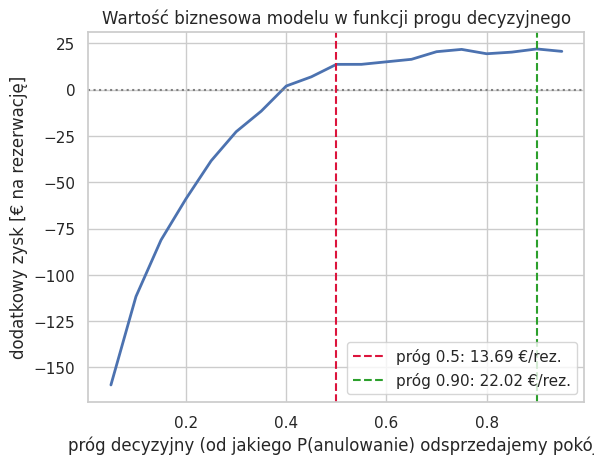

próg 0.50:  +13.69 € na rezerwację  =>  +685 tys. € rocznie
próg 0.90:  +22.02 € na rezerwację  =>  +1,101 tys. € rocznie


In [17]:
# --- założenia biznesowe (zmieńcie i zobaczcie, co się dzieje!) ---
WARTOSC_REZERWACJI = float((df["adr"] * (df["stays_in_week_nights"] + df["stays_in_weekend_nights"])).median())
ZYSK_TP  = 0.60 * WARTOSC_REZERWACJI    # odsprzedaż z rabatem
KOSZT_FP = 1.50 * WARTOSC_REZERWACJI    # relokacja + rekompensata + reputacja
REZERWACJI_ROCZNIE = 50_000             # skala biznesu obu hoteli

print(f"mediana wartości rezerwacji: {WARTOSC_REZERWACJI:.0f} €")

def zysk_modelu(model, X, y, prog=0.5):
    """dodatkowy zysk [€ na rezerwację] — każda rezerwacja liczona po swojej wartości"""
    wartosc = X["adr"] * (X["stays_in_week_nights"] + X["stays_in_weekend_nights"])
    dzialamy = model.predict_proba(X)[:, 1] >= prog
    zysk_tp  = 0.60 * wartosc[dzialamy & (y == 1)].sum()
    koszt_fp = 1.50 * wartosc[dzialamy & (y == 0)].sum()
    return (zysk_tp - koszt_fp) / len(y)

# zysk przy naiwnym progu 0.5 vs progi dobrane biznesowo
progi = np.linspace(0.05, 0.95, 19)
zyski = [zysk_modelu(model, X_val, y_val, prog=p) for p in progi]
najlepszy_prog = progi[int(np.argmax(zyski))]

plt.plot(progi, zyski, lw=2)
plt.axhline(0, color="gray", ls=":")
plt.axvline(0.5, color="crimson", ls="--", label=f"próg 0.5: {zysk_modelu(model, X_val, y_val, 0.5):.2f} €/rez.")
plt.axvline(najlepszy_prog, color="tab:green", ls="--", label=f"próg {najlepszy_prog:.2f}: {max(zyski):.2f} €/rez.")
plt.xlabel("próg decyzyjny (od jakiego P(anulowanie) odsprzedajemy pokój)")
plt.ylabel("dodatkowy zysk [€ na rezerwację]")
plt.title("Wartość biznesowa modelu w funkcji progu decyzyjnego")
plt.legend(); plt.show()

for prog in [0.5, najlepszy_prog]:
    z = zysk_modelu(model, X_val, y_val, prog)
    print(f"próg {prog:.2f}:  {z:+.2f} € na rezerwację  =>  {z * REZERWACJI_ROCZNIE / 1000:+,.0f} tys. € rocznie")

### Co z tego wynika — i jak używać modelu w praktyce

Trzy wnioski z wykresu (przedyskutujcie w grupie):

1. **Optymalny próg ≠ 0.5.** Skoro FP kosztuje 2.5× więcej niż zarabia TP, opłaca się działać tylko przy dużej pewności — matematycznie: gdy `p × 60% > (1−p) × 150%`, czyli p > ~0.71. Model z najlepszym accuracy może zarabiać **mniej** niż model gorszy, ale lepiej "wycelowany".
2. **Zmieńcie założenia** (np. tańsza rekompensata, mniejszy rabat odsprzedaży) i zobaczcie, jak wędruje optymalny próg — to pokazuje, że wdrożenie ML to decyzja biznesowa, nie tylko techniczna.

**Jak taki model działa w prawdziwym hotelu:**

* **Kontrolowany overbooking** — codzienny raport: suma P(anulowanie) na najbliższe daty mówi, ile pokoi można "dosprzedać" ponad stan.
* **Retencja wysokiego ryzyka** — zamiast odsprzedawać, można do rezerwacji z p > progu zadzwonić. Inne koszty FP → inny optymalny próg, ta sama maszyneria.
* **Polityka depozytów** — segmenty o wysokim ryzyku dostają przy rezerwacji wymóg przedpłaty; model wskazuje, które.
* **Planowanie operacyjne** — prognoza realnego obłożenia (rezerwacje minus przewidziane anulacje) zasila grafiki personelu i zakupy.

Wspólny mianownik: model **nie podejmuje decyzji** — dostarcza prawdopodobieństwo, a decyzję (i próg) ustawia biznes, znając swoje koszty.